# Caso 3 — Clustering con Circles (`KMeans`, `DBSCAN`, `SpectralClustering`)
**Curso:** Aprendizaje de Máquina (IX ciclo, grupo B) — UNAP  
**Responsable:** Gutierrez Arratia Kevin Diego

## 1. Librerías y datos

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel

sys.path.insert(0, str(Path.cwd().parent / "src"))
from clustering_utils import (
    PALETTE_CLUSTERS,
    set_minimalist_style,
    evaluate_clustering,
    compute_elbow_and_internal_curves,
    plot_scatter_minimal,
    plot_elbow_and_validation_panel,
    plot_metrics_bar_comparison,
)

set_minimalist_style()

X_raw, y = make_circles(n_samples=500, factor=0.5, noise=0.05, random_state=42)
X = StandardScaler().fit_transform(X_raw)
c0, c1 = X[y == 0].mean(axis=0), X[y == 1].mean(axis=0)
print(f"Centroide C0: {c0.round(4)} | Centroide C1: {c1.round(4)}")

Centroide C0: [-0.0042  0.0044] | Centroide C1: [ 0.0042 -0.0044]


## 2. Entrenamiento y métricas

In [2]:
km = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
y_km = km.fit_predict(X)
y_db = DBSCAN(eps=0.25, min_samples=5).fit_predict(X)
y_sc = SpectralClustering(n_clusters=2, affinity="rbf", gamma=10.0, random_state=42).fit_predict(X)

df_circles = pd.DataFrame([
    evaluate_clustering(X, y, y_km, "K-Means (k=2)", "Circles", km.inertia_),
    evaluate_clustering(X, y, y_db, "DBSCAN (eps=0.25)", "Circles"),
    evaluate_clustering(X, y, y_sc, "Spectral (RBF, γ=10)", "Circles"),
])
display(df_circles)

,Dataset,Modelo,Clusters_Detectados,Puntos_Ruido,Ruido_Pct,ARI,V_Measure,Homogeneidad,Completitud,Silhouette,Davies_Bouldin,Inercia_WCSS
0,Circles,K-Means (k=2),2,0,0.0,-0.002,0.0,0.0,0.0,0.3531,1.1825,634.33
1,Circles,DBSCAN (eps=0.25),2,0,0.0,1.000,1.0,1.0,1.0,0.1126,220.3668,NaN
2,Circles,"Spectral (RBF, γ=10)",2,0,0.0,1.000,1.0,1.0,1.0,0.1126,220.3668,NaN


## 3. Visualización de clusters

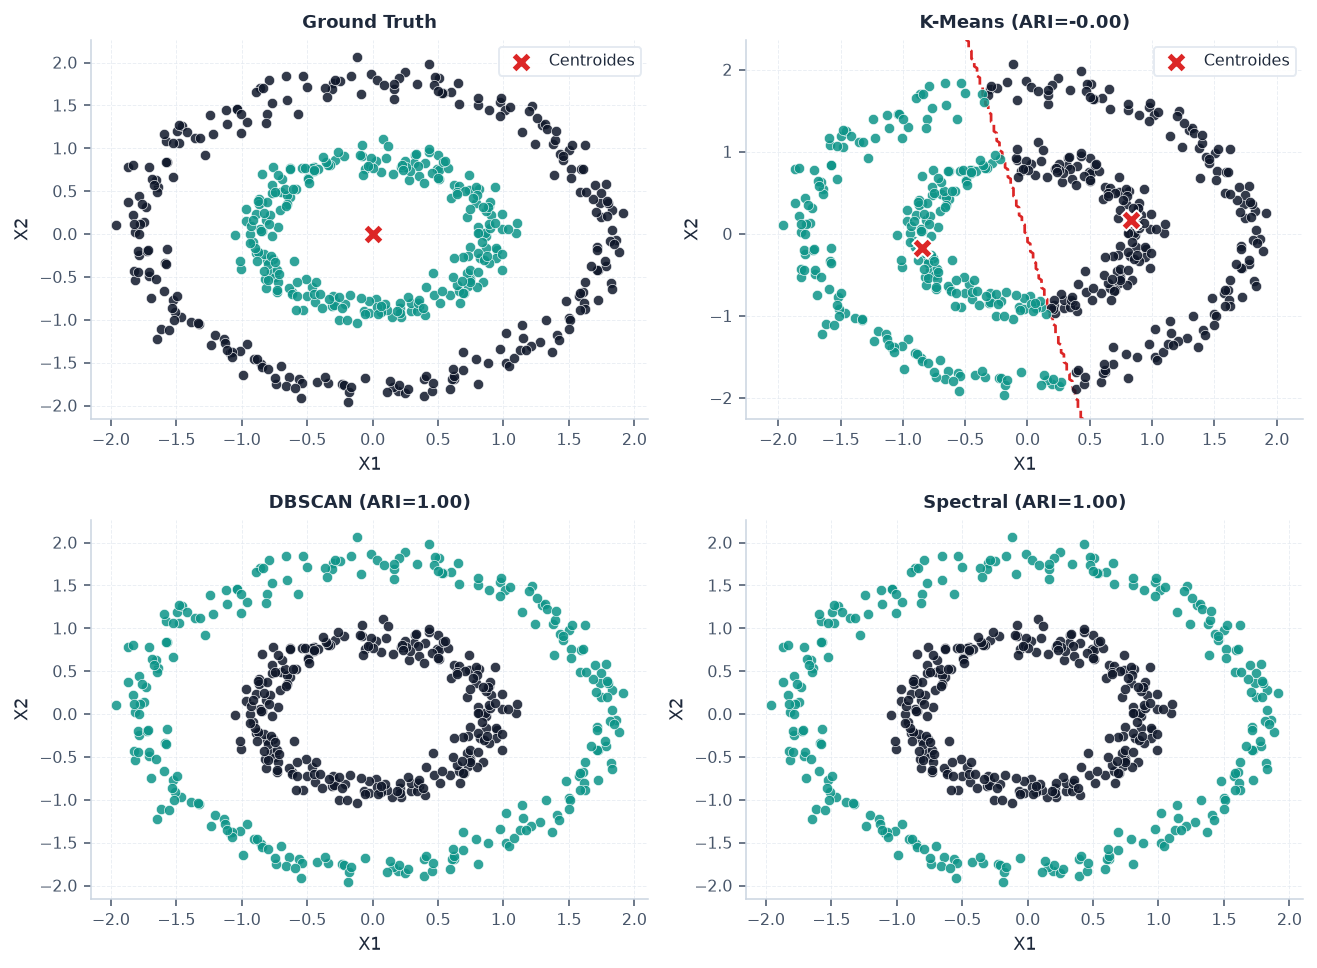

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.0))
plot_scatter_minimal(axes[0, 0], X, y, "Ground Truth", centroids_2d=np.vstack([c0, c1]))

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 200),
    np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 200),
)
Z_km = km.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0, 1].contour(xx, yy, Z_km, levels=[0.5], colors=["#DC2626"], linewidths=1.4, linestyles="--")

plot_scatter_minimal(axes[0, 1], X, y_km, f"K-Means (ARI={df_circles.loc[0, 'ARI']:.2f})", centroids_2d=km.cluster_centers_)
plot_scatter_minimal(axes[1, 0], X, y_db, f"DBSCAN (ARI={df_circles.loc[1, 'ARI']:.2f})")
plot_scatter_minimal(axes[1, 1], X, y_sc, f"Spectral (ARI={df_circles.loc[2, 'ARI']:.2f})")
fig.tight_layout()
plt.show()

## 4. Proyección espectral (Vector de Fiedler) y métricas

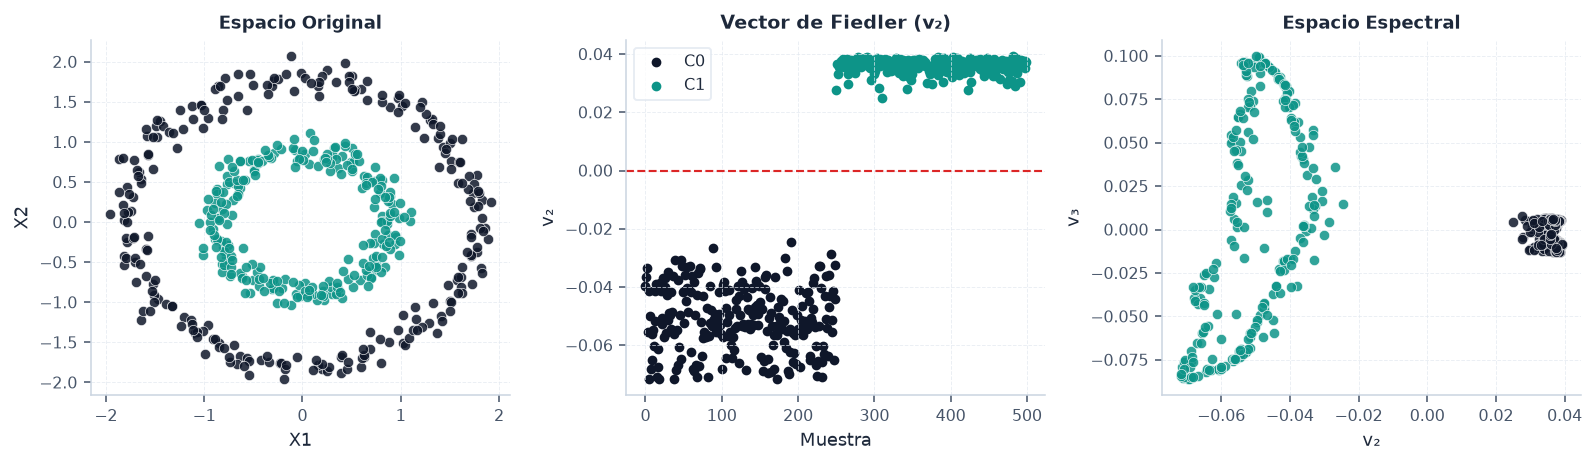

,k,Inercia_WCSS,Silhouette,Davies_Bouldin
0,1,1000.0000,NaN,NaN
1,2,634.3300,0.3531,1.1825
2,3,383.7898,0.3885,0.8389
3,4,270.6974,0.3779,0.8145
4,5,213.5725,0.3579,0.8513
5,6,180.3324,0.3379,0.9109
6,7,160.7871,0.3138,0.9877
7,8,141.7075,0.3554,0.9021
8,9,126.1377,0.3867,0.7938


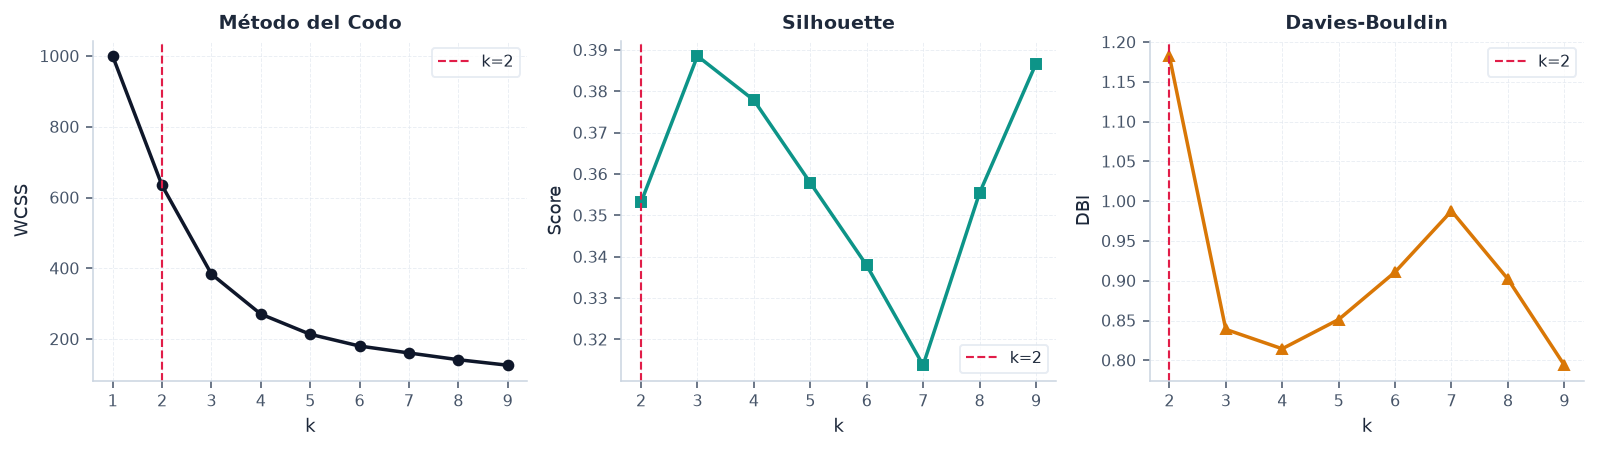

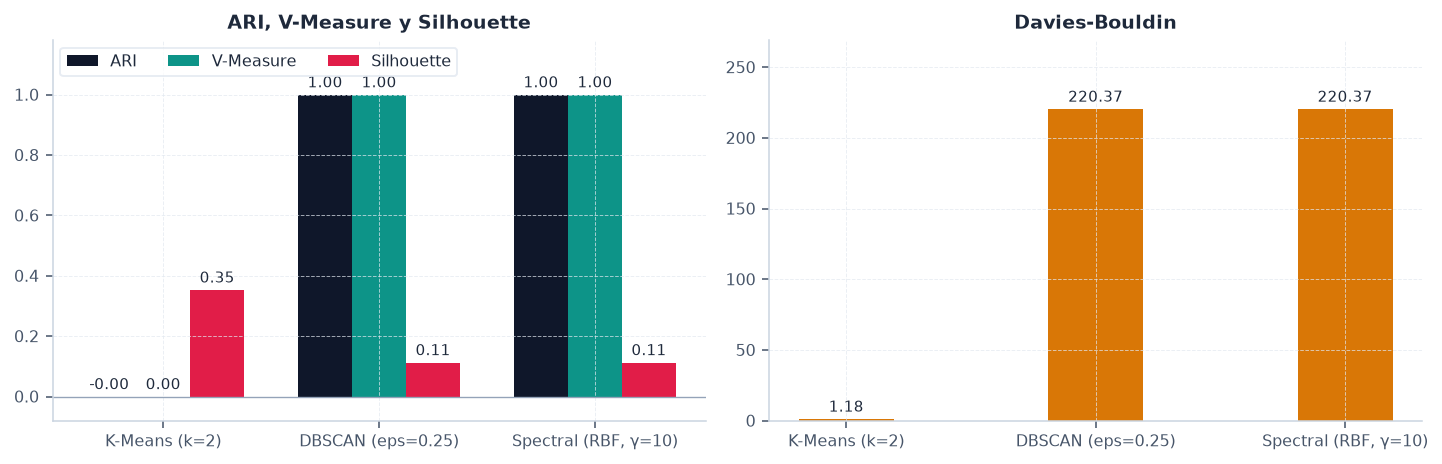

In [4]:
W = rbf_kernel(X, gamma=10.0)
D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(W.sum(axis=1), 1e-12)))
L_sym = np.eye(len(X)) - D_inv_sqrt @ W @ D_inv_sqrt
_, eigvecs = eigh(L_sym)
v2, v3 = eigvecs[:, 1], eigvecs[:, 2]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
plot_scatter_minimal(axes[0], X, y, "Espacio Original")
order_idx = np.argsort(y)
for c_i in [0, 1]:
    mask_c = y[order_idx] == c_i
    axes[1].scatter(np.where(mask_c)[0], v2[order_idx][mask_c], c=PALETTE_CLUSTERS[c_i], s=16, label=f"C{c_i}")
axes[1].axhline(0, color="#DC2626", ls="--", lw=1.1)
axes[1].set_title("Vector de Fiedler (v₂)")
axes[1].set_xlabel("Muestra")
axes[1].set_ylabel("v₂")
axes[1].legend(loc="best")

plot_scatter_minimal(axes[2], np.column_stack([v2, v3]), y_sc, "Espacio Espectral", xlabel="v₂", ylabel="v₃")
fig.tight_layout()
plt.show()

df_curves = compute_elbow_and_internal_curves(X, range(1, 10))
display(df_curves.round(4))
plot_elbow_and_validation_panel(df_curves, optimal_k=2)
plt.show()

plot_metrics_bar_comparison(df_circles)
plt.show()